# Regime models: a feasibility study

**The idea:**
- one model per solar-wind regime (slow, intermediate, fast stream, stream arrival, CME);
- a classifier that predicts the regime at t0 and picks the model.

**The catch:** a run's regime is defined by what happens during its 72 target hours
(`training.solar_wind_events.classify_runs`), so the router has to predict the future. This
notebook measures whether that can pay off before anything is built.

**Setup** (`python -m training.regime_models`):
- **Folds:** the six yearly walk-forward folds (2019-10 → 2025-10, `training.folds.YEARLY`). Each fold fits on everything before its start; the eval year is not used.
- **Score:** per-run mean TIMSE relative to persistence; the summary is the geometric mean over folds, the selection objective.
- **Global models:** the shipped linear model and XGBoost hybrid, refitted per fold. They reproduce the selection scores (0.4387 and 0.4258).
- **Per-regime models:** the same two configs fitted on one regime's training runs only. A regime with fewer than 200 six-hourly fit runs would fall back to the global model; none did.
- **Classifiers:** P(regime) at t0 from the hybrid's 30 regressors plus the speed terms (last speed, and the mean and maximum of each recurrence term over the 72 target hours):
  - multinomial logistic regression;
  - XGBoost (`multi:softprob`, depth 3, 200 rounds).

  Settings are fixed, not tuned. Only fit runs whose target hours end before the fold start are labelled.

**Routing methods:**

| Method | Forecast |
|---|---|
| oracle | the model of the run's true regime: the ceiling |
| hard | the model of the most probable regime |
| soft | Σ P(regime) × that regime's model |
| shrunk soft | a × soft + (1 − a) × global model, one weight a picked on the folds |
| prior | Σ climatological share × regime model: routing with no information |

**Decision rule (set in the plan):** build the regime system only if a realistic method beats the
hybrid's fold score by more than 2% and wins at least 4 of the 6 folds.

1. Regimes
2. The oracle ceiling, and the cost of the wrong model
3. Can the regime be predicted at t0?
4. Realistic scores
5. Findings

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import linear_model as tl
from training import regime_models as rm
from training import solar_wind_events as ev

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.width", 200)

ROUTES = rm.ROUTES
COLORS = dict(zip(ROUTES, ["#c0392b", "#e67e22", "#8e44ad", "#7f8c8d", "#2980b9"], strict=True))
folds = rm.load_folds()
labels = pd.read_pickle(rm.CACHE_DIR / "labels.pkl")
table = pd.read_csv(rm.EXPERIMENTS / "regime_models.csv").set_index("fold")
shrink = rm.choose_shrink(folds)


def fmt(df, digits=3):
    return df.style.format(precision=digits)


def run_scores(f, forecast):
    # each scored run's TIMSE relative to the fold's mean persistence TIMSE
    return tl.run_scores(forecast, f["y"], f["q"])[f["scored"]] / f["ref"]


print(f"{len(folds)} folds, {sum(len(f['t0s']) for f in folds.values())} validation runs")
print("shrink weights on the soft forecast:", shrink)

6 folds, 8768 validation runs
shrink weights on the soft forecast: {('logistic', 'linear'): 0.5, ('logistic', 'hybrid'): 0.3, ('xgboost', 'linear'): 0.5, ('xgboost', 'hybrid'): 0.3}


## 1. Regimes

Shares of hourly runs per training year (October to October), with the 6 detected regimes. Possible
CMEs are routed with the CMEs.

regime,CME,possible CME,stream arrival,fast stream,slow wind,intermediate
2016-10,7.1,9.0,23.9,13.0,20.3,26.7
2017-10,7.3,4.2,20.8,1.7,29.4,36.5
2018-10,3.4,2.0,15.1,2.4,45.5,31.5
2019-10,7.0,1.8,8.0,0.7,61.5,21.0
2020-10,14.4,7.5,16.3,1.8,34.6,25.5
2021-10,14.7,8.3,25.9,4.5,16.2,30.4
2022-10,19.7,9.9,20.1,3.6,18.6,28.1
2023-10,28.4,3.3,8.0,1.1,35.9,23.2
2024-10,13.8,1.9,22.8,7.0,15.6,38.9


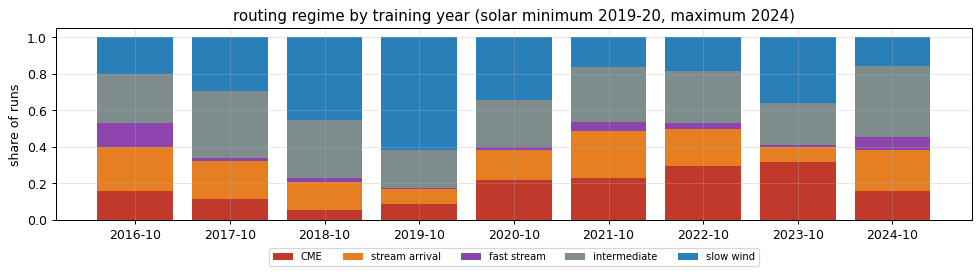

In [2]:
year = labels.index.year - (labels.index.month < 10) - ((labels.index.month == 10)
                                                        & (labels.index.day < 20))
share = pd.crosstab(year, labels["regime"], normalize="index")[ev.REGIMES]
share.index = [f"{y}-10" for y in share.index]
display(fmt(share * 100, 1))

fig, ax = plt.subplots(figsize=(11, 3.2))
bottom = np.zeros(len(share))
routes = pd.crosstab(year, labels["route"], normalize="index")[ROUTES]
for r in ROUTES:
    ax.bar(share.index, routes[r], bottom=bottom, color=COLORS[r], label=r)
    bottom += routes[r].to_numpy()
ax.set_ylabel("share of runs")
ax.set_title("routing regime by training year (solar minimum 2019-20, maximum 2024)")
ax.legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()

In [3]:
# independent episodes: runs of consecutive 6-hourly validation runs with the same regime
rows = {}
for y, f in folds.items():
    route = pd.Series(np.asarray(ROUTES)[f["route"]])
    episodes = route[route != route.shift()].value_counts()
    rows[f"{y}-10"] = {**{f"fit runs: {r}": f["fit_runs"][r] for r in ROUTES},
                       **{f"val episodes: {r}": int(episodes.get(r, 0)) for r in ROUTES}}
display(pd.DataFrame(rows).T)

,fit runs: CME,fit runs: stream arrival,fit runs: fast stream,fit runs: intermediate,fit runs: slow wind,val episodes: CME,val episodes: stream arrival,val episodes: fast stream,val episodes: intermediate,val episodes: slow wind
2019-10,484,873,252,1385,1374,7,11,3,22,22
2020-10,613,990,261,1694,2274,19,21,5,35,30
2021-10,920,1230,283,2071,2788,22,35,13,45,23
2022-10,1255,1607,348,2516,3026,21,27,6,38,25
2023-10,1696,1899,401,2931,3285,24,14,3,33,27
2024-10,2158,2016,417,3261,3824,13,30,18,44,17


## 2. The oracle ceiling, and the cost of the wrong model

**Per fold:** the global hybrid, the oracle (each run gets its true regime's model) and the
best realistic method.

,global linear,global hybrid,oracle linear,oracle hybrid,shrunk soft xgboost hybrid
fold,,,,,
2019-10,0.4292,0.3939,0.2706,0.2680,0.3723
2020-10,0.3666,0.3614,0.2473,0.2477,0.3473
2021-10,0.5000,0.4921,0.4665,0.4694,0.5045
2022-10,0.4648,0.4601,0.3580,0.3677,0.4626
2023-10,0.5587,0.5548,0.4172,0.4155,0.5521
2024-10,0.3490,0.3331,0.2855,0.2701,0.3367
geometric mean,0.4387,0.4258,0.3317,0.3298,0.4215


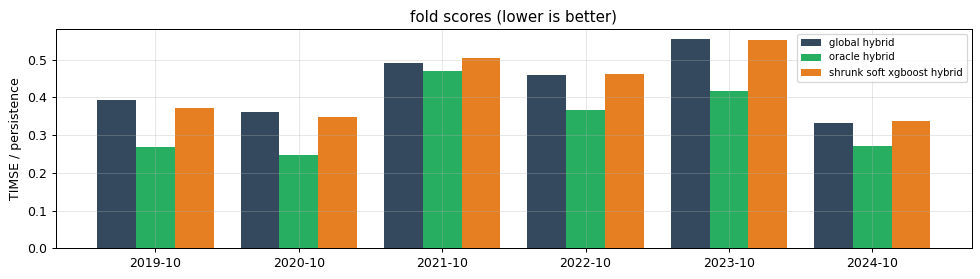

In [4]:
best = "shrunk soft xgboost hybrid"
cols = ["global linear", "global hybrid", "oracle linear", "oracle hybrid", best]
per_fold = table[cols].copy()
per_fold.loc["geometric mean"] = [rm.geo(table[c]) for c in cols]
display(fmt(per_fold, 4))

fig, ax = plt.subplots(figsize=(11, 3.2))
x = np.arange(len(table))
for i, (c, color) in enumerate(zip(["global hybrid", "oracle hybrid", best],
                                   ["#34495e", "#27ae60", "#e67e22"], strict=True)):
    ax.bar(x + (i - 1) * 0.27, table[c], 0.27, color=color, label=c)
ax.set_xticks(x, table.index)
ax.set_ylabel("TIMSE / persistence")
ax.legend(fontsize=8)
ax.set_title("fold scores (lower is better)")
fig.tight_layout()

**The cost matrix.** For the runs of each true regime (rows), the pooled TIMSE of each regime's
hybrid (columns) relative to the global hybrid on the same runs, pooled over the six folds. The
diagonal is what the oracle gains; the rest is what a wrong call costs.

In [5]:
cost = pd.DataFrame(index=ROUTES, columns=ROUTES + ["global"], dtype=float)
share_err = {}
for i, true in enumerate(ROUTES):
    glob, by = 0.0, np.zeros(len(ROUTES))
    for f in folds.values():
        sel = f["route"][f["scored"]] == i
        glob += run_scores(f, f["global_hybrid"])[sel].sum()
        for j in range(len(ROUTES)):
            by[j] += run_scores(f, f["regime_hybrid"][j])[sel].sum()
    cost.loc[true, ROUTES] = by / glob
    cost.loc[true, "global"] = 1.0
    share_err[true] = glob
cost["share of global error"] = pd.Series(share_err) / sum(share_err.values())
cost["runs"] = [sum(int((f["route"][f["scored"]] == i).sum()) for f in folds.values())
                for i in range(len(ROUTES))]
display(fmt(cost, 2).background_gradient(subset=ROUTES, cmap="RdYlGn_r", vmin=0.3, vmax=3))

,CME,stream arrival,fast stream,intermediate,slow wind,global,share of global error,runs
CME,1.06,1.09,1.43,1.44,2.70,1.00,0.34,1903
stream arrival,1.07,0.79,0.99,1.69,3.93,1.00,0.25,1476
fast stream,1.22,0.77,0.60,1.80,4.46,1.00,0.04,267
intermediate,1.36,1.45,2.53,0.85,1.69,1.00,0.20,2453
slow wind,1.81,2.25,3.80,0.89,0.22,1.00,0.18,2662


**Example runs** in the 2024 fold: the global hybrid and the five regime hybrids. The panel title
gives the true regime and the XGBoost classifier's probabilities.

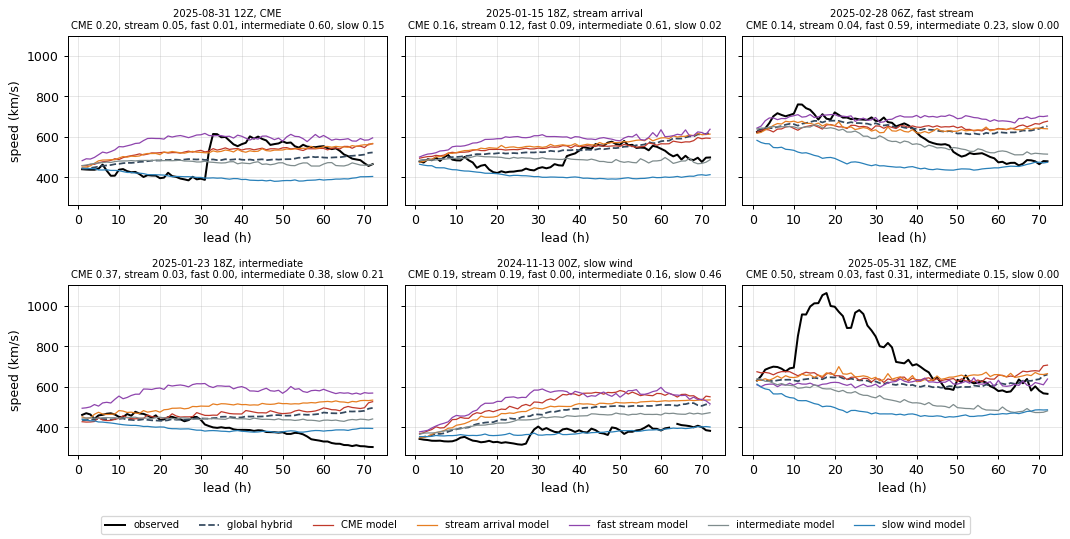

In [6]:
f = folds[2024]
rng = np.random.default_rng(3)
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
picks = [rng.choice(np.flatnonzero(f["route"] == i)) for i in range(len(ROUTES))]
worst = np.where(f["scored"], tl.run_scores(f["global_hybrid"], f["y"], f["q"]), 0)
picks.append(int(np.argmax(worst)))  # the hybrid's worst run
lead = np.arange(1, 73)
for ax, k in zip(axes.ravel(), picks, strict=True):
    ax.plot(lead, f["y"][k], color="k", lw=1.6, label="observed")
    ax.plot(lead, f["global_hybrid"][k], color="#34495e", lw=1.4, ls="--", label="global hybrid")
    for j, r in enumerate(ROUTES):
        ax.plot(lead, f["regime_hybrid"][j][k], color=COLORS[r], lw=1, label=f"{r} model")
    p = ", ".join(f"{r.split()[0]} {f['p_xgboost'][k, j]:.2f}" for j, r in enumerate(ROUTES))
    ax.set_title(f"{pd.Timestamp(f['t0s'][k]):%Y-%m-%d %H}Z, {ROUTES[f['route'][k]]}\n{p}",
                 fontsize=8)
    ax.set_xlabel("lead (h)")
axes[0, 0].set_ylabel("speed (km/s)")
axes[1, 0].set_ylabel("speed (km/s)")
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, ncol=7, fontsize=8, loc="lower center")
fig.tight_layout(rect=(0, 0.05, 1, 1))

## 3. Can the regime be predicted at t0?

**Confusion matrices,** pooled over the six folds (rows: true regime; columns: the most probable
regime; each row sums to 1).

In [7]:
true = np.concatenate([f["route"] for f in folds.values()])
probs = {c: np.vstack([f[f"p_{c}"] for f in folds.values()]) for c in rm.CLASSIFIERS}
prior = np.vstack([np.repeat(f["prior"][None], len(f["route"]), 0) for f in folds.values()])
for c in rm.CLASSIFIERS:
    pred = probs[c].argmax(axis=1)
    conf = pd.crosstab(pd.Categorical(np.asarray(ROUTES)[true], ROUTES),
                       pd.Categorical(np.asarray(ROUTES)[pred], ROUTES),
                       normalize="index", dropna=False)
    conf.index.name, conf.columns.name = "true", f"{c}: predicted"
    display(fmt(conf, 2).background_gradient(cmap="Blues", vmin=0, vmax=1))

logistic: predicted,CME,stream arrival,fast stream,intermediate,slow wind
true,,,,,
CME,0.38,0.17,0.03,0.24,0.17
stream arrival,0.27,0.33,0.01,0.16,0.24
fast stream,0.16,0.08,0.33,0.42,0.00
intermediate,0.22,0.10,0.01,0.54,0.12
slow wind,0.17,0.13,0.00,0.10,0.60


xgboost: predicted,CME,stream arrival,fast stream,intermediate,slow wind
true,,,,,
CME,0.36,0.13,0.02,0.24,0.26
stream arrival,0.21,0.31,0.02,0.17,0.29
fast stream,0.13,0.06,0.36,0.45,0.00
intermediate,0.17,0.11,0.01,0.56,0.15
slow wind,0.17,0.10,0.00,0.07,0.67


In [8]:
def log_loss(p, y):
    return float(-np.mean(np.log(np.clip(p[np.arange(len(y)), y], 1e-6, 1))))


rows = {}
for c in rm.CLASSIFIERS:
    pred = probs[c].argmax(axis=1)
    row = {"accuracy": (pred == true).mean(), "log loss": log_loss(probs[c], true),
           "log loss, climatology": log_loss(prior, true)}
    for i, r in enumerate(ROUTES):
        row[f"recall {r}"] = (pred[true == i] == i).mean()
        row[f"precision {r}"] = (true[pred == i] == i).mean() if (pred == i).any() else np.nan
    quiet = np.isin(pred, [ROUTES.index("intermediate"), ROUTES.index("slow wind")])
    for r in ("CME", "stream arrival"):
        row[f"{r} called quiet"] = quiet[true == ROUTES.index(r)].mean()
    rows[c] = row
display(fmt(pd.DataFrame(rows), 3))

# per fold: log loss against climatology
skill = pd.DataFrame({
    c: {f"{y}-10": 1 - log_loss(f[f"p_{c}"], f["route"])
        / log_loss(np.repeat(f["prior"][None], len(f["route"]), 0), f["route"])
        for y, f in folds.items()} for c in rm.CLASSIFIERS})
skill.columns = [f"{c}: log-loss skill vs climatology" for c in skill.columns]
display(fmt(skill, 3))

,logistic,xgboost
accuracy,0.482,0.502
log loss,1.314,1.203
"log loss, climatology",1.495,1.495
recall CME,0.384,0.356
precision CME,0.336,0.360
recall stream arrival,0.329,0.313
precision stream arrival,0.343,0.373
recall fast stream,0.333,0.360
precision fast stream,0.461,0.505
recall intermediate,0.541,0.562


,logistic: log-loss skill vs climatology,xgboost: log-loss skill vs climatology
2019-10,0.301,0.314
2020-10,0.125,0.162
2021-10,-0.011,0.132
2022-10,0.141,0.224
2023-10,-0.019,0.119
2024-10,0.212,0.232


**Reliability** of the XGBoost classifier, pooled over folds: the observed frequency of each regime
against its predicted probability (10 bins). The diagonal is perfect calibration.

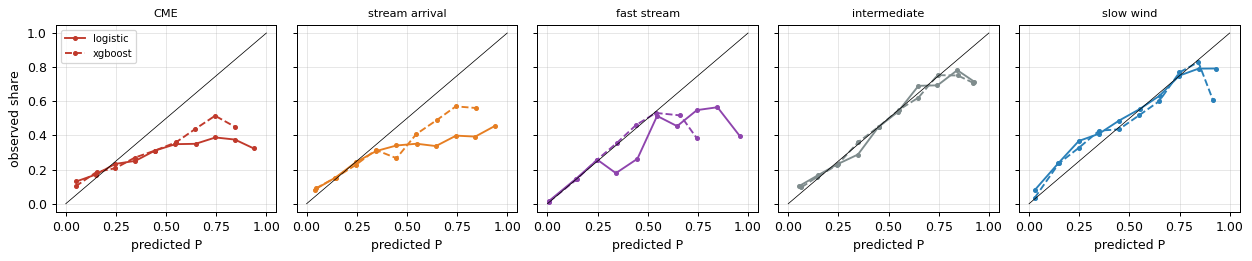

In [9]:
fig, axes = plt.subplots(1, len(ROUTES), figsize=(14, 3), sharey=True)
bins = np.linspace(0, 1, 11)
for i, (ax, r) in enumerate(zip(axes, ROUTES, strict=True)):
    for c, ls in zip(rm.CLASSIFIERS, ["-", "--"], strict=True):
        p = probs[c][:, i]
        b = np.clip(np.digitize(p, bins) - 1, 0, 9)
        df = pd.DataFrame({"b": b, "p": p, "hit": true == i}).groupby("b").agg(
            p=("p", "mean"), hit=("hit", "mean"), n=("hit", "size"))
        df = df[df["n"] >= 20]
        ax.plot(df["p"], df["hit"], marker="o", ms=3, ls=ls, color=COLORS[r], label=c)
    ax.plot([0, 1], [0, 1], color="k", lw=0.6)
    ax.set_title(r, fontsize=9)
    ax.set_xlabel("predicted P")
axes[0].set_ylabel("observed share")
axes[0].legend(fontsize=8)
fig.tight_layout()

**What the classifier sees before a CME.** The XGBoost classifier's P(CME) around the start of
each CME episode in the validation folds (hours from the first run labelled CME). A run is
labelled CME as soon as any of its target hours is CME-affected, so the label starts up to 72 h
before the arrival.

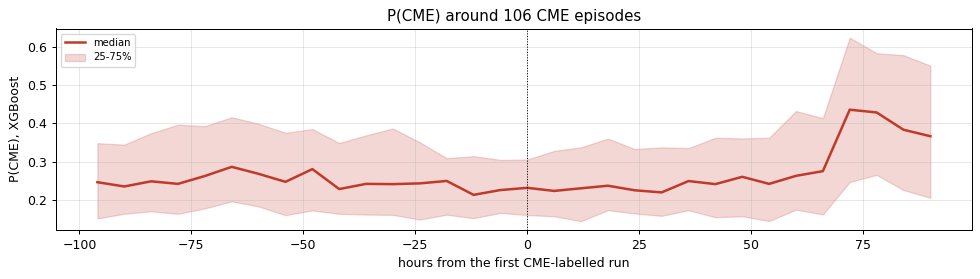

In [10]:
curves = []
for f in folds.values():
    is_cme = f["route"] == 0
    starts = np.flatnonzero(is_cme & ~np.r_[False, is_cme[:-1]])
    for s in starts:
        idx = np.arange(s - 16, s + 16)
        ok = (idx >= 0) & (idx < len(is_cme))
        row = np.full(len(idx), np.nan)
        row[ok] = f["p_xgboost"][idx[ok], 0]
        curves.append(row)
curves = np.array(curves)
hours = np.arange(-16, 16) * 6
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(hours, np.nanmedian(curves, axis=0), color=COLORS["CME"], lw=2, label="median")
ax.fill_between(hours, *np.nanpercentile(curves, [25, 75], axis=0), color=COLORS["CME"],
                alpha=0.2, label="25-75%")
ax.axvline(0, color="k", lw=0.8, ls=":")
ax.set_xlabel("hours from the first CME-labelled run")
ax.set_ylabel("P(CME), XGBoost")
ax.set_title(f"P(CME) around {len(curves)} CME episodes")
ax.legend(fontsize=8)
fig.tight_layout()

## 4. Realistic scores

Every method, as the geometric mean over the six folds, relative to the global hybrid, and the
number of folds it beats the hybrid in.

In [11]:
summary = pd.DataFrame({
    "fold score": {c: rm.geo(table[c]) for c in table.columns},
    "vs global hybrid": {c: rm.geo(table[c]) / rm.geo(table["global hybrid"]) - 1
                         for c in table.columns},
    "folds won vs hybrid": {c: int((table[c] < table["global hybrid"]).sum())
                            for c in table.columns},
}).sort_values("fold score")
display(summary.style.format({"fold score": "{:.4f}", "vs global hybrid": "{:+.1%}"}))

,fold score,vs global hybrid,folds won vs hybrid
oracle hybrid,0.3298,-22.6%,6
oracle linear,0.3317,-22.1%,6
shrunk soft xgboost hybrid,0.4215,-1.0%,3
shrunk soft logistic hybrid,0.4222,-0.8%,3
global hybrid,0.4258,+0.0%,0
shrunk soft xgboost linear,0.4295,+0.9%,2
shrunk soft logistic linear,0.4303,+1.1%,2
global linear,0.4387,+3.0%,0
soft xgboost linear,0.4429,+4.0%,1
soft logistic linear,0.4432,+4.1%,1


**By true regime:** pooled TIMSE of each method relative to the global hybrid on the runs of that
regime, over the six folds. Where routing helps and where misrouting hurts.

In [12]:
methods = ["oracle hybrid", "soft xgboost hybrid", "shrunk soft xgboost hybrid",
           "hard xgboost hybrid", "soft logistic hybrid", "prior hybrid"]
acc = {m: np.zeros(len(ROUTES)) for m in methods + ["global hybrid"]}
for f in folds.values():
    fc = rm.forecasts(f, shrink)
    route = f["route"][f["scored"]]
    for m in acc:
        s = run_scores(f, fc[m])
        for i in range(len(ROUTES)):
            acc[m][i] += s[route == i].sum()
by_regime = pd.DataFrame({m: acc[m] / acc["global hybrid"] for m in methods}, index=ROUTES)
total = {m: acc[m].sum() / acc["global hybrid"].sum() for m in methods}
by_regime.loc["all runs (pooled)"] = total
display(fmt(by_regime, 3).background_gradient(cmap="RdYlGn_r", vmin=0.5, vmax=1.5))

,oracle hybrid,soft xgboost hybrid,shrunk soft xgboost hybrid,hard xgboost hybrid,soft logistic hybrid,prior hybrid
CME,1.056,1.123,1.019,1.312,1.143,1.354
stream arrival,0.794,1.294,1.060,1.661,1.243,1.658
fast stream,0.597,1.088,1.010,1.278,1.072,1.857
intermediate,0.851,0.938,0.959,1.135,0.946,0.883
slow wind,0.219,0.663,0.876,0.726,0.711,0.791
all runs (pooled),0.785,1.048,0.992,1.262,1.051,1.259


**Shrinkage.** The fold score of a × soft + (1 − a) × global hybrid as a function of a. The weight
is picked on the same six folds, so the best point is slightly optimistic.

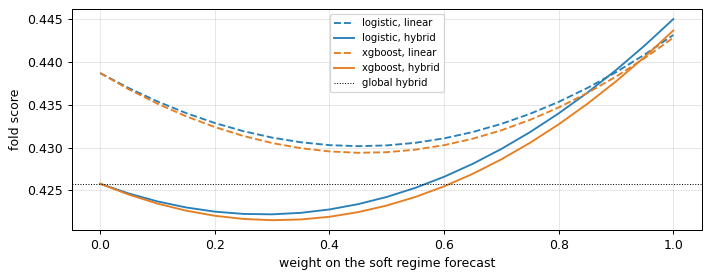

In [13]:
grid = np.linspace(0, 1, 21)
fig, ax = plt.subplots(figsize=(8, 3.2))
for c, color in zip(rm.CLASSIFIERS, ["#2980b9", "#e67e22"], strict=True):
    for m, ls in zip(rm.MEMBERS, ["--", "-"], strict=True):
        s = [rm.geo([rm.ratio(f, a * rm.mix(f[f"p_{c}"], f[f"regime_{m}"])
                              + (1 - a) * f[f"global_{m}"]) for f in folds.values()])
             for a in grid]
        ax.plot(grid, s, color=color, ls=ls, label=f"{c}, {m}")
ax.axhline(rm.geo(table["global hybrid"]), color="k", lw=0.8, ls=":", label="global hybrid")
ax.set_xlabel("weight on the soft regime forecast")
ax.set_ylabel("fold score")
ax.legend(fontsize=8)
fig.tight_layout()

## 5. Findings

### Verdict: don't build the regime system

The best realistic method is soft XGBoost routing shrunk towards the hybrid (30% regime models, 70%
global hybrid). It scores 0.4215 against the hybrid's 0.4258, which is 1.0% better, but it wins
only 3 of the 6 folds, and its weight was picked on those same folds. The rule needed a gain above 2% in at least 4 folds.
Unshrunk soft routing is 4% worse than the hybrid, and hard routing 22–26% worse.

### (i) The oracle ceiling is large, but most of it is the label leaking the future

- **Oracle routing** scores 0.330, 22.6% better than the hybrid, in all six folds.
- **Most of the gain comes from quiet wind,** and that's a property of the label, not of the models:
  - "slow wind" means the speed stays below 450 km/s for the next 72 h;
  - a model fitted only on such runs learns that the speed won't rise, and on those runs it reaches 0.22× the hybrid's TIMSE;
  - fast stream gives 0.60×, stream arrival 0.79×, intermediate 0.85×.
- **The CME model doesn't beat the global hybrid even on true CME runs** (1.06×). CMEs carry the largest share of the hybrid's error (34%), and they are where specialisation helps least.

### (ii) The wrong model is expensive, and the costs are lopsided

| | Slow-wind model on a true… | Cost vs the hybrid |
|---|---|---|
| | CME | 2.7× |
| | stream arrival | 3.9× |
| | fast stream | 4.5× |

- **Calling a slow run a CME** costs 1.8×, a stream arrival 2.3×.
- **The gain from the right call** on slow wind (0.22×) is smaller than the loss from the wrong one.

### (iii) The regime can't be predicted well enough at t0

| | Logistic | XGBoost |
|---|---|---|
| Accuracy (5 regimes) | 48% | 50% |
| Log-loss skill vs climatology | 0.12 | 0.20 |
| CME recall / precision | 38% / 34% | 36% / 36% |
| Stream arrival recall / precision | 33% / 34% | 31% / 37% |
| **CME runs called quiet** (slow or intermediate) | 42% | **50%** |
| **Stream-arrival runs called quiet** | 40% | **46%** |

- **The classifier sees a CME only once it has arrived.** Around the start of each CME episode (the first run whose 72 h window touches the CME), the median P(CME) stays at 0.23–0.28 (climatology: 0.14) until about 72 h later, when the CME is at L1. Then it rises to 0.44. Nothing at t0 announces the CME in advance; the flare and coronal inputs don't give enough warning.
- **The skill varies by fold:** the logistic model is no better than climatology in 2021 and 2023.

### (iv) Where soft routing helps and hurts (pooled TIMSE vs the global hybrid, by true regime)

| True regime | Soft (XGBoost) | Shrunk soft |
|---|---|---|
| slow wind | **0.66** | 0.88 |
| intermediate | 0.94 | 0.96 |
| fast stream | 1.09 | 1.01 |
| CME | 1.12 | 1.02 |
| stream arrival | **1.29** | 1.06 |
| all runs | 1.05 | 0.99 |

Soft routing does what the oracle suggests on quiet wind, but it pays for it on the stream arrivals
and CMEs it fails to foresee. Shrinking towards the hybrid gives back most of both sides.

### What this means

1. **Regime models won't be built.** The oracle's headline gain mainly reflects that the regime labels are defined from the future target window.
2. **The one transferable signal:** on quiet wind, a "no stream coming" probability lowers the error. That is the 72 h quiet-wind over-forecast found in every eval analysis. A more direct route is to give the existing hybrid inputs that predict the absence of a stream, rather than to route between models.
3. **Not tried:** regime probabilities as extra inputs to the hybrid's trees (the plan's optional step, kept for when soft routing showed promise). The classifier sees the same inputs as the hybrid's trees, so it's unlikely to add much.

### Caveats

- **Classifiers:** their settings were fixed, not tuned. A tuned classifier could do somewhat better, but not enough to close a 50% "CME called quiet" rate.
- **Regime labels** come from the in-situ event detection (`training.solar_wind_events`), with thresholds fixed in advance.
- **The eval year was not used.**